# 03 · Modelo perfil → preferencia (Etapa A)

**Pregunta:** ¿el perfil de estrés y bienestar de una persona permite predecir qué experiencias le ayudarían a descansar?

1. **Comparar ML contra un baseline.** Regresión logística por tipo de experiencia (con todo el perfil, o solo estrés y bienestar) contra *popularidad* (recomendar a todos lo más elegido). Validación cruzada 5-fold repetida 20 veces, separando personas; métrica nDCG@3 y Precision@3.
2. **Estimar el efecto del estrés en cada tipo**, con odds ratio por +1 DE, IC 95 % y corrección por comparaciones múltiples (FDR).
3. **Construir el modelo final**: popularidad + solo los efectos con evidencia (q < 0.05). El artefacto queda en `models/welltur_preferencias_v1.json` y es el que usa el recomendador.

In [1]:
import sys
from pathlib import Path
SRC = next(p for p in [Path('src'), Path('../src'), Path('MODELO/src')] if (p / 'encuesta_etl.py').exists()).resolve()
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lab_graficas import aplicar_estilo, guardar, SERIES, TEXTO_2, ETIQUETAS_PREF, ETIQUETAS_W
aplicar_estilo()
pd.set_option('display.max_columns', 50)

In [2]:
import json
from encuesta_etl import OUT_DEFAULT
from modelo_preferencias import evaluar_ml, estimar_efectos, entrenar_y_guardar, probabilidades, pesos_w
df = pd.read_csv(OUT_DEFAULT)
ev = evaluar_ml(df)
res = pd.DataFrame(ev['metodos']).T
res

,ndcg@3,precision@3,dif_vs_popularidad,ic95_dif,wilcoxon_p
perfil_completo,0.591,0.5178,-0.054,"[-0.0861, -0.0234]",0.0014
solo_estres_bienestar,0.6409,0.5465,-0.0041,"[-0.0208, 0.012]",0.8299
popularidad,0.645,0.5375,NaN,NaN,NaN


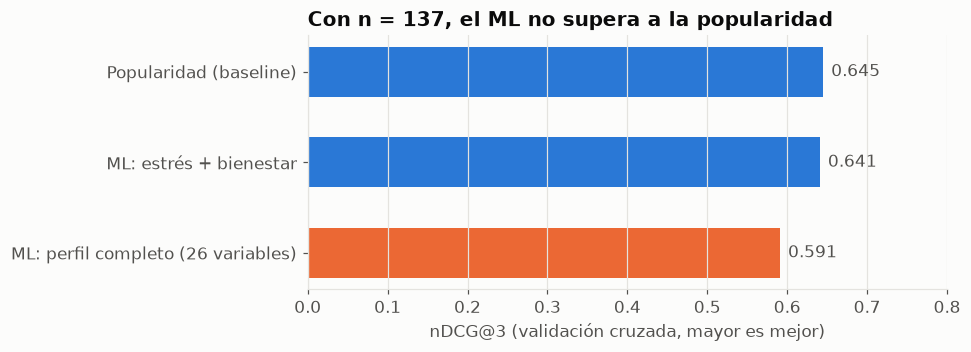

In [3]:
nombres = {'popularidad': 'Popularidad (baseline)', 'solo_estres_bienestar': 'ML: estrés + bienestar', 'perfil_completo': 'ML: perfil completo (26 variables)'}
fig, ax = plt.subplots(figsize=(7.5, 3))
orden = ['popularidad', 'solo_estres_bienestar', 'perfil_completo']
vals = [ev['metodos'][m]['ndcg@3'] for m in orden]
ax.barh([nombres[m] for m in orden][::-1], vals[::-1], color=[SERIES[0], SERIES[0], SERIES[1]][::-1], height=0.55)
for i, v in enumerate(vals[::-1]):
    ax.text(v + 0.01, i, f'{v:.3f}', va='center', color=TEXTO_2)
ax.set_xlim(0, 0.8); ax.set_xlabel('nDCG@3 (validación cruzada, mayor es mejor)'); ax.grid(axis='y', visible=False)
ax.set_title('Con n = 137, el ML no supera a la popularidad')
guardar(fig, '03_ml_vs_popularidad');

**Lectura:** el modelo con todo el perfil *sobreajusta* (es peor que la popularidad, IC 95 % de la diferencia por debajo de 0) y el de estrés + bienestar empata con ella. Con 137 personas no hay datos suficientes para personalizar con muchas variables; por eso el modelo final solo usa los efectos que tienen evidencia estadística.

In [4]:
efectos = estimar_efectos(df)
vista = efectos[['preferencia', 'prevalencia', 'or_por_de', 'ic95_or', 'p', 'q_fdr']].copy()
vista['preferencia'] = vista['preferencia'].map(ETIQUETAS_PREF)
vista

,preferencia,prevalencia,or_por_de,ic95_or,p,q_fdr
0,"Cascadas, ríos y naturaleza",0.651,1.145,"[0.791, 1.656]",0.4738,0.7160
1,Caminatas en bosque/montaña,0.595,1.035,"[0.724, 1.48]",0.8484,0.8484
2,"Relajación, meditación, respiración",0.429,1.740,"[1.181, 2.563]",0.0051,0.0408
3,Hospedaje tranquilo,0.421,1.194,"[0.834, 1.709]",0.3340,0.7160
4,Cultura y artesanía,0.325,1.213,"[0.83, 1.772]",0.3177,0.7160
5,Gastronomía local,0.246,1.152,"[0.764, 1.736]",0.4992,0.7160
6,Recreación de baja intensidad,0.222,1.143,"[0.748, 1.747]",0.5370,0.7160
7,Convivencia con comunidades rurales,0.159,0.919,"[0.569, 1.485]",0.7306,0.8350


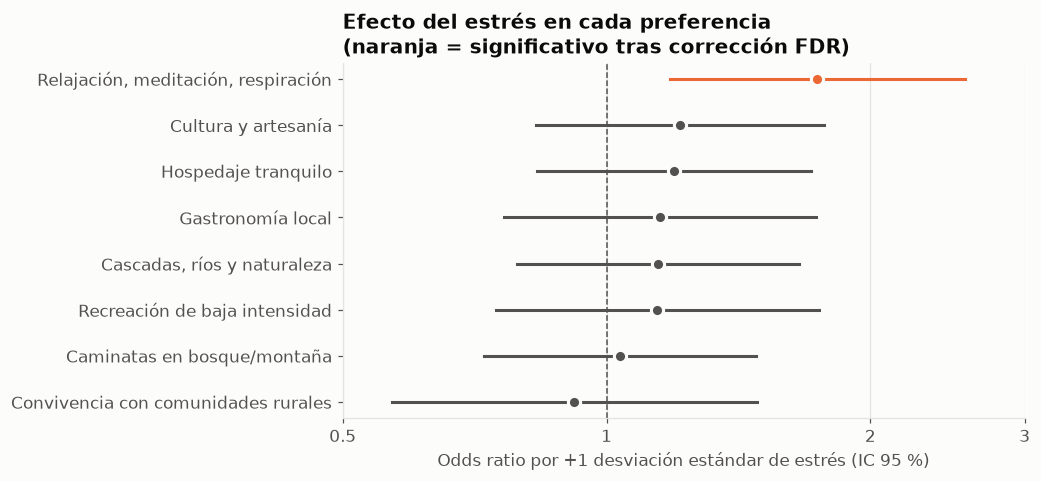

In [5]:
e = efectos.sort_values('or_por_de')
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, fila in enumerate(e.itertuples()):
    color = SERIES[1] if fila.q_fdr < 0.05 else TEXTO_2
    ax.plot(fila.ic95_or, [i, i], color=color, linewidth=2)
    ax.plot(fila.or_por_de, i, 'o', color=color, markersize=8, markeredgecolor='#fcfcfb', markeredgewidth=2)
ax.axvline(1, color=TEXTO_2, linewidth=1, linestyle='--')
ax.set_yticks(range(len(e)), [ETIQUETAS_PREF[p] for p in e['preferencia']])
ax.set_xscale('log'); ax.set_xticks([0.5, 1, 2, 3], ['0.5', '1', '2', '3']); ax.minorticks_off()
ax.set_xlabel('Odds ratio por +1 desviación estándar de estrés (IC 95 %)'); ax.grid(axis='y', visible=False)
ax.set_title('Efecto del estrés en cada preferencia\n(naranja = significativo tras corrección FDR)')
guardar(fig, '03_efecto_estres_forest');

## Modelo final y cómo cambia la recomendación con el estrés

In [6]:
artefacto = entrenar_y_guardar()
pd.DataFrame(artefacto['tipos']).T[['prevalencia', 'or_por_de', 'q_fdr', 'usa_estres', 'intercepto', 'beta_estres_z']]

,prevalencia,or_por_de,q_fdr,usa_estres,intercepto,beta_estres_z
pref_cascadas_rios,0.651,1.145,0.716,False,0.6234,0.0
pref_caminatas,0.595,1.035,0.8484,False,0.3847,0.0
pref_relajacion,0.429,1.74,0.0408,True,-0.3088,0.5537
pref_hospedaje_tranquilo,0.421,1.194,0.716,False,-0.3187,0.0
pref_cultural,0.325,1.213,0.716,False,-0.7309,0.0
pref_gastronomia,0.246,1.152,0.716,False,-1.1201,0.0
pref_baja_intensidad,0.222,1.143,0.716,False,-1.254,0.0
pref_comunidades,0.159,0.919,0.835,False,-1.6657,0.0


In [7]:
niveles = {'Estrés bajo (20)': 20, 'Estrés medio (50)': 50, 'Estrés alto (80)': 80}
pesos = pd.DataFrame({k: pesos_w(probabilidades(artefacto, v)) for k, v in niveles.items()})
pesos.index = [ETIQUETAS_W[w] for w in pesos.index]
(pesos * 100).round(1)

,Estrés bajo (20),Estrés medio (50),Estrés alto (80)
W1 Pausa y descanso,14.3,15.1,16.0
W2 Naturaleza,31.9,29.3,26.8
W3 Movimiento,22.9,21.1,19.3
W4 Mente-cuerpo,4.9,8.5,12.0
W5 Culinaria,5.5,5.0,4.6
W6 Cultura,13.5,12.4,11.4
W7 Autocuidado,7.1,8.6,10.0


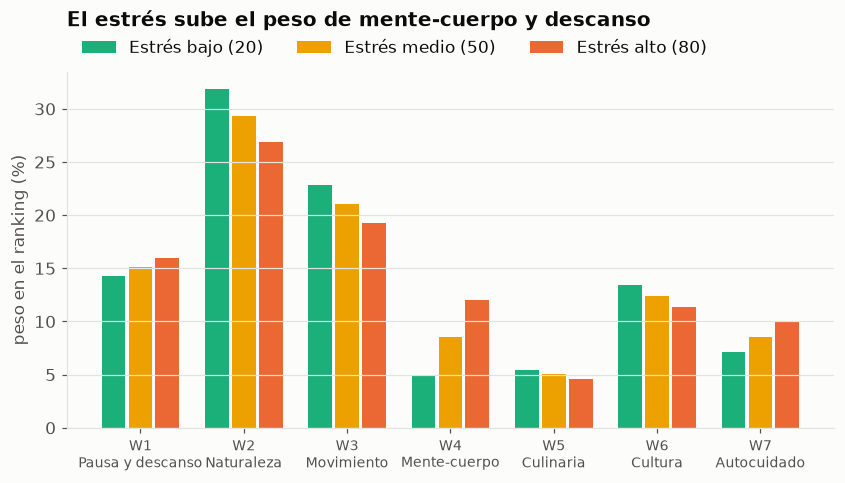

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ancho = 0.26
for j, col in enumerate(pesos.columns):
    ax.bar(np.arange(len(pesos)) + (j - 1) * ancho, pesos[col] * 100, width=ancho - 0.03, color=SERIES[[2, 3, 1][j]], label=col)
ax.set_xticks(np.arange(len(pesos)), [w.replace(' ', '\n', 1) for w in pesos.index], fontsize=9)
ax.set_ylabel('peso en el ranking (%)'); ax.grid(axis='x', visible=False); ax.legend(frameon=False, ncols=3, loc='lower left', bbox_to_anchor=(0, 1.0))
ax.set_title('El estrés sube el peso de mente-cuerpo y descanso', pad=30)
guardar(fig, '03_pesos_w_por_estres');